# 数组可视化操作

## 定义二维可视化数组操作函数

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from matplotlib import cm 
import os

# 如果文件夹不存在，创建文件夹
if not os.path.isdir("Figures"):
    os.makedirs("Figures")

In [1]:
def visualize_2D(array, title, vmax, vmin):
    
    fig_width  = math.ceil(array.shape[1] * 0.5)
    fig_length = math.ceil(array.shape[0] * 0.5)
    
    fig, ax = plt.subplots(figsize=(fig_width, fig_length))
    # 注意，seaborn.heatmap() 目前只能接受2D数组
    # 本书中，一维数组可视化时用圆圈
    # 可视化时，只有二维、三维数组用方块
    
    sns.heatmap(array, 
                vmax = vmax,
                vmin = vmin,
                annot = True,      # 增加注释
                fmt = ".2f",       # 注释数值的格式
                square = True,     # 热图方格为正方形
                cmap = 'RdYlBu_r', # 指定色谱
                linewidths = .5,   # 方格线宽
                cbar = False,      # 不显示色谱条
                yticklabels=False, # 不显示纵轴标签
                xticklabels=False, # 不显示横轴标签
                ax = ax)           # 指定绘制热图的轴
    
    fig.savefig('Figures/' + title + '.svg', format='svg')

# 定义绘制一元数组可视化函数

def visualize_1D(array, title, vmax, vmin):
    fig, ax = plt.subplots()
    
    cmap = plt.colormaps.get_cmap("RdYlBu")
    
    array_norm = (array - vmin) / (vmax - vmin)

    colors = cmap(array_norm)

    for idx in range(len(array)):

        circle_idx = plt.Circle((idx, 0), 0.5, facecolor=colors[idx], edgecolor = 'w')
        ax.add_patch(circle_idx)
        ax.text(idx, 0, s = "{:.1f}".format(array[idx]),
                horizontalalignment = 'center',
                verticalalignment = 'center')

    ax.set_xlim(-0.6, 0.6 + len(array))
    ax.set_ylim(-0.6, 0.6)
    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    fig.savefig('Figures/' + title + '.svg', format='svg')

## 一维数组运算法则   加、减、乘、 除

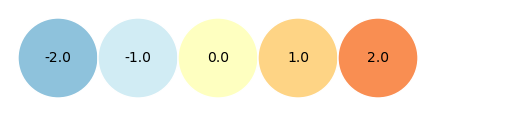

In [4]:
a_1D = np.arange(-2,2+1)
visualize_1D(a_1D, '一维数组', -4, 4)

In [7]:
all_twos = 2*np.ones_like(a_1D)
all_twos

array([2, 2, 2, 2, 2])

In [8]:
np.full_like(a_1D, 2)

array([2, 2, 2, 2, 2])

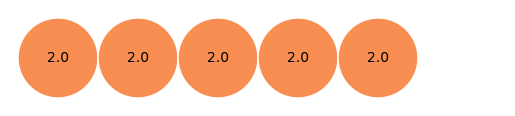

In [9]:
visualize_1D(all_twos, '一维数组，全2', -4, 4)

In [20]:
np.add(a_1D, all_twos)

np.subtract(a_1D, all_twos)

np.multiply(a_1D, all_twos)

np.divide(a_1D, all_twos)

np.power(a_1D, all_twos)



array([4, 1, 0, 1, 4])

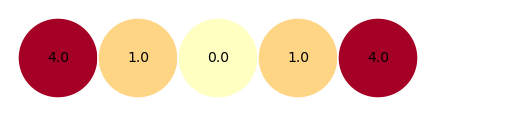

In [19]:
visualize_1D(a_1D ** all_twos, '一维数组，加法', -4, 4)

In [18]:
a_1D **all_twos

array([4, 1, 0, 1, 4])

## 二维数组运算法则   加、减、乘、 除

In [21]:
a_2D = np.random.uniform(-1, 1, (4,6))
a_2D

array([[ 0.61445201, -0.6296993 ,  0.05729295, -0.14303408, -0.43993092,
        -0.34083862],
       [-0.26077175,  0.84079238, -0.14346566,  0.81711179,  0.61867091,
        -0.68719507],
       [-0.60953262, -0.7984153 , -0.53991859,  0.29613378,  0.03902553,
        -0.09349337],
       [-0.00887555,  0.8437453 , -0.37548106,  0.95112537, -0.71780788,
        -0.13664713]])

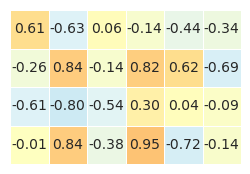

In [22]:
visualize_2D(a_2D, '二维数组', 3, -3)

In [23]:
all_twos_2D = np.full_like(a_2D, 2)
all_twos_2D

array([[2., 2., 2., 2., 2., 2.],
       [2., 2., 2., 2., 2., 2.],
       [2., 2., 2., 2., 2., 2.],
       [2., 2., 2., 2., 2., 2.]])

In [32]:
a_2D + all_twos_2D
a_2D - all_twos_2D

a_2D * all_twos_2D

a_2D / all_twos_2D

a_2D ** all_twos_2D

array([[3.77551275e-01, 3.96521203e-01, 3.28248158e-03, 2.04587492e-02,
        1.93539216e-01, 1.16170967e-01],
       [6.80019075e-02, 7.06931827e-01, 2.05823962e-02, 6.67671685e-01,
        3.82753691e-01, 4.72237063e-01],
       [3.71530013e-01, 6.37466993e-01, 2.91512080e-01, 8.76952154e-02,
        1.52299170e-03, 8.74101078e-03],
       [7.87753000e-05, 7.11906136e-01, 1.40986024e-01, 9.04639467e-01,
        5.15248157e-01, 1.86724382e-02]])

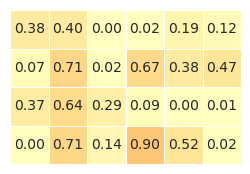

In [33]:
visualize_2D(a_2D ** all_twos_2D, '二维加法', 3, -3)

## 数组运算规则  广播原则

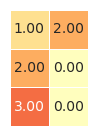

In [37]:
visualize_2D(np.array([[1], [2], [3]]), '列向量，二维', 5, -5)




In [38]:
a_1D

array([-2, -1,  0,  1,  2])

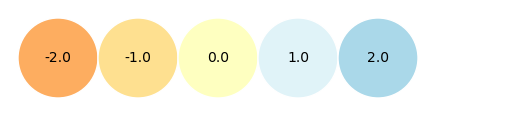

In [39]:
visualize_1D(a_1D  , '一维数组 ', 5, -5)




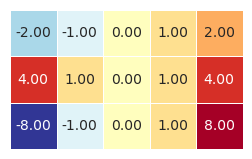

In [43]:
visualize_2D(a_1D**np.array([[1],[2],[3]]) , '一维数组 ', 5, -5)




In [44]:
a_2D + 2

array([[2.61445201, 1.3703007 , 2.05729295, 1.85696592, 1.56006908,
        1.65916138],
       [1.73922825, 2.84079238, 1.85653434, 2.81711179, 2.61867091,
        1.31280493],
       [1.39046738, 1.2015847 , 1.46008141, 2.29613378, 2.03902553,
        1.90650663],
       [1.99112445, 2.8437453 , 1.62451894, 2.95112537, 1.28219212,
        1.86335287]])

In [45]:
np.linspace(-1,1,6)


array([-1. , -0.6, -0.2,  0.2,  0.6,  1. ])

In [46]:
np.broadcast_to(np.linspace(-1,1,6), (4, 6))

array([[-1. , -0.6, -0.2,  0.2,  0.6,  1. ],
       [-1. , -0.6, -0.2,  0.2,  0.6,  1. ],
       [-1. , -0.6, -0.2,  0.2,  0.6,  1. ],
       [-1. , -0.6, -0.2,  0.2,  0.6,  1. ]])

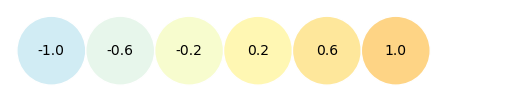

In [47]:
visualize_1D(np.linspace(-1,1,6), '一维数组，6个元素', -4, 4)

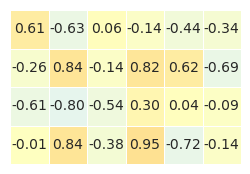

In [51]:
visualize_2D(a_2D , '二维数组 ', 5, -5)

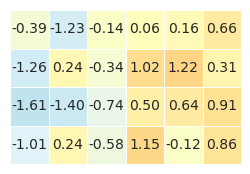

In [50]:
visualize_2D(a_2D + np.linspace(-1,1,6), '二维数组和一维数组，加法', 5, -5)

## 向量运算    使用reshape() 

In [52]:
np.linspace(-1,1,6).reshape(1,-1)

array([[-1. , -0.6, -0.2,  0.2,  0.6,  1. ]])

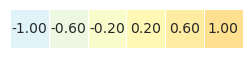

In [53]:
visualize_2D(np.linspace(-1,1,6).reshape(1,-1), '行向量，6个元素', 5, -5)

In [62]:
np.linspace(-3,3,9).reshape(1,-1)

array([[-3.  , -2.25, -1.5 , -0.75,  0.  ,  0.75,  1.5 ,  2.25,  3.  ]])

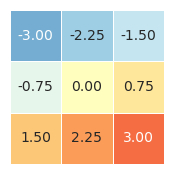

In [58]:
visualize_2D(np.linspace(-3,3,9).reshape(3,-3), '行向量，6个元素', 5, -5)

In [59]:
a_2D * np.linspace(-1,1,6)

array([[-0.61445201,  0.37781958, -0.01145859, -0.02860682, -0.26395855,
        -0.34083862],
       [ 0.26077175, -0.50447543,  0.02869313,  0.16342236,  0.37120254,
        -0.68719507],
       [ 0.60953262,  0.47904918,  0.10798372,  0.05922676,  0.02341532,
        -0.09349337],
       [ 0.00887555, -0.50624718,  0.07509621,  0.19022507, -0.43068473,
        -0.13664713]])

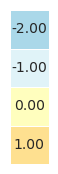

In [60]:
visualize_2D(np.array([[-2], [-1], [0], [1]]), '列向量，4个元素', 5, -5)

In [63]:
A_3D = np.arange(-30, 30).reshape(3,4,5)
A_3D

array([[[-30, -29, -28, -27, -26],
        [-25, -24, -23, -22, -21],
        [-20, -19, -18, -17, -16],
        [-15, -14, -13, -12, -11]],

       [[-10,  -9,  -8,  -7,  -6],
        [ -5,  -4,  -3,  -2,  -1],
        [  0,   1,   2,   3,   4],
        [  5,   6,   7,   8,   9]],

       [[ 10,  11,  12,  13,  14],
        [ 15,  16,  17,  18,  19],
        [ 20,  21,  22,  23,  24],
        [ 25,  26,  27,  28,  29]]])

In [64]:
A_3D + 2

array([[[-28, -27, -26, -25, -24],
        [-23, -22, -21, -20, -19],
        [-18, -17, -16, -15, -14],
        [-13, -12, -11, -10,  -9]],

       [[ -8,  -7,  -6,  -5,  -4],
        [ -3,  -2,  -1,   0,   1],
        [  2,   3,   4,   5,   6],
        [  7,   8,   9,  10,  11]],

       [[ 12,  13,  14,  15,  16],
        [ 17,  18,  19,  20,  21],
        [ 22,  23,  24,  25,  26],
        [ 27,  28,  29,  30,  31]]])

In [65]:
np.arange(1,5+1)

array([1, 2, 3, 4, 5])

In [66]:
A_3D + np.array([[[1]],[[2]],[[3]]])

array([[[-29, -28, -27, -26, -25],
        [-24, -23, -22, -21, -20],
        [-19, -18, -17, -16, -15],
        [-14, -13, -12, -11, -10]],

       [[ -8,  -7,  -6,  -5,  -4],
        [ -3,  -2,  -1,   0,   1],
        [  2,   3,   4,   5,   6],
        [  7,   8,   9,  10,  11]],

       [[ 13,  14,  15,  16,  17],
        [ 18,  19,  20,  21,  22],
        [ 23,  24,  25,  26,  27],
        [ 28,  29,  30,  31,  32]]])

In [67]:
A_2D = np.random.randint(0,10, size = (4,6))

In [68]:
A_2D

array([[9, 6, 1, 6, 3, 1],
       [1, 9, 9, 5, 8, 6],
       [6, 5, 6, 1, 0, 0],
       [6, 6, 1, 1, 4, 3]])

In [73]:
import seaborn as sns
from sklearn.datasets import load_iris
os.environ["SEABORN_DATA"] = "/home/lee/ogs-py310/iris_data/seaborn-data-master/seaborn-data-master"
iris = load_iris()

iris_data_array = iris.data

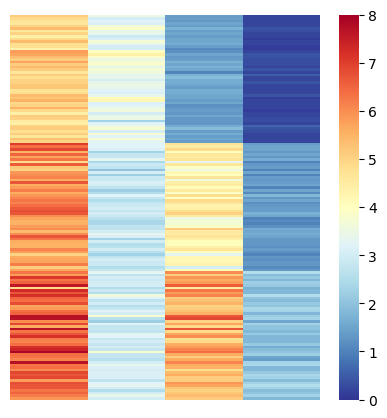

In [74]:
import seaborn as sns
fig, ax = plt.subplots(figsize = (5,5))
sns.heatmap(iris_data_array,   # 鸢尾花数据数组
            cmap = 'RdYlBu_r', # 指定色谱
            ax = ax,           # 指定轴
            vmax = 8,          # 色谱最大值
            vmin = 0,          # 色谱最小值
            xticklabels = [],  # 不显示横轴标签
            yticklabels = [],  # 不显示纵轴标签
            cbar = True)       # 显示色谱条

fig.savefig('Figures/鸢尾花数据热图.svg', format='svg')

In [75]:
A_2D.max()

np.int64(9)

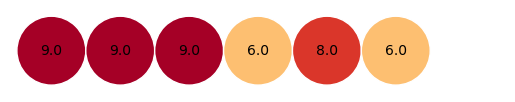

In [76]:
visualize_1D(A_2D.max(axis = 0), '沿axis = 0，最大值', 0, 9)

In [77]:
A_2D.max(axis = 1)

array([9, 9, 6, 6])

In [80]:
A_2D

array([[9, 6, 1, 6, 3, 1],
       [1, 9, 9, 5, 8, 6],
       [6, 5, 6, 1, 0, 0],
       [6, 6, 1, 1, 4, 3]])

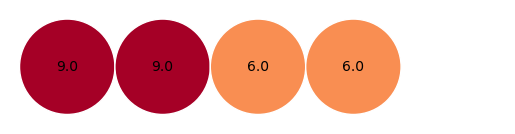

In [81]:
visualize_1D(A_2D.max(axis = 1), '沿axis = 1，最大值', 0, 8)

In [82]:
iris_data_array.max(axis = 1)

array([5.1, 4.9, 4.7, 4.6, 5. , 5.4, 4.6, 5. , 4.4, 4.9, 5.4, 4.8, 4.8,
       4.3, 5.8, 5.7, 5.4, 5.1, 5.7, 5.1, 5.4, 5.1, 4.6, 5.1, 4.8, 5. ,
       5. , 5.2, 5.2, 4.7, 4.8, 5.4, 5.2, 5.5, 4.9, 5. , 5.5, 4.9, 4.4,
       5.1, 5. , 4.5, 4.4, 5. , 5.1, 4.8, 5.1, 4.6, 5.3, 5. , 7. , 6.4,
       6.9, 5.5, 6.5, 5.7, 6.3, 4.9, 6.6, 5.2, 5. , 5.9, 6. , 6.1, 5.6,
       6.7, 5.6, 5.8, 6.2, 5.6, 5.9, 6.1, 6.3, 6.1, 6.4, 6.6, 6.8, 6.7,
       6. , 5.7, 5.5, 5.5, 5.8, 6. , 5.4, 6. , 6.7, 6.3, 5.6, 5.5, 5.5,
       6.1, 5.8, 5. , 5.6, 5.7, 5.7, 6.2, 5.1, 5.7, 6.3, 5.8, 7.1, 6.3,
       6.5, 7.6, 4.9, 7.3, 6.7, 7.2, 6.5, 6.4, 6.8, 5.7, 5.8, 6.4, 6.5,
       7.7, 7.7, 6. , 6.9, 5.6, 7.7, 6.3, 6.7, 7.2, 6.2, 6.1, 6.4, 7.2,
       7.4, 7.9, 6.4, 6.3, 6.1, 7.7, 6.3, 6.4, 6. , 6.9, 6.7, 6.9, 5.8,
       6.8, 6.7, 6.7, 6.3, 6.5, 6.2, 5.9])

In [83]:
iris_data_array.sum(axis = 0)

array([876.5, 458.6, 563.7, 179.9])

In [84]:
iris_data_array.sum(axis = 1)

array([10.2,  9.5,  9.4,  9.4, 10.2, 11.4,  9.7, 10.1,  8.9,  9.6, 10.8,
       10. ,  9.3,  8.5, 11.2, 12. , 11. , 10.3, 11.5, 10.7, 10.7, 10.7,
        9.4, 10.6, 10.3,  9.8, 10.4, 10.4, 10.2,  9.7,  9.7, 10.7, 10.9,
       11.3,  9.7,  9.6, 10.5, 10. ,  8.9, 10.2, 10.1,  8.4,  9.1, 10.7,
       11.2,  9.5, 10.7,  9.4, 10.7,  9.9, 16.3, 15.6, 16.4, 13.1, 15.4,
       14.3, 15.9, 11.6, 15.4, 13.2, 11.5, 14.6, 13.2, 15.1, 13.4, 15.6,
       14.6, 13.6, 14.4, 13.1, 15.7, 14.2, 15.2, 14.8, 14.9, 15.4, 15.8,
       16.4, 14.9, 12.8, 12.8, 12.6, 13.6, 15.4, 14.4, 15.5, 16. , 14.3,
       14. , 13.3, 13.7, 15.1, 13.6, 11.6, 13.8, 14.1, 14.1, 14.7, 11.7,
       13.9, 18.1, 15.5, 18.1, 16.6, 17.5, 19.3, 13.6, 18.3, 16.8, 19.4,
       16.8, 16.3, 17.4, 15.2, 16.1, 17.2, 16.8, 20.4, 19.5, 14.7, 18.1,
       15.3, 19.2, 15.7, 17.8, 18.2, 15.6, 15.8, 16.9, 17.6, 18.2, 20.1,
       17. , 15.7, 15.7, 19.1, 17.7, 16.8, 15.6, 17.5, 17.8, 17.4, 15.5,
       18.2, 18.2, 17.2, 15.7, 16.7, 17.3, 15.8])

In [85]:
np.average(iris_data_array)

np.float64(3.4644999999999997)

In [86]:
np.var(iris_data_array)

np.float64(3.896056416666667)

In [87]:
np.var(iris_data_array, axis = 0)

array([0.68112222, 0.18871289, 3.09550267, 0.57713289])

In [88]:
np.var(iris_data_array, axis = 0, ddof = 1)

array([0.68569351, 0.18997942, 3.11627785, 0.58100626])

In [89]:
np.std(iris_data_array, axis = 0)

array([0.82530129, 0.43441097, 1.75940407, 0.75969263])

In [90]:
np.cov(iris_data_array.T, ddof = 1)

array([[ 0.68569351, -0.042434  ,  1.27431544,  0.51627069],
       [-0.042434  ,  0.18997942, -0.32965638, -0.12163937],
       [ 1.27431544, -0.32965638,  3.11627785,  1.2956094 ],
       [ 0.51627069, -0.12163937,  1.2956094 ,  0.58100626]])

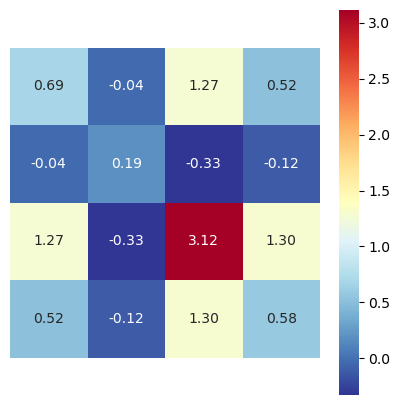

In [91]:

fig, ax = plt.subplots(figsize = (5,5))
sns.heatmap(np.cov(iris_data_array.T, ddof = 1),   
            cmap = 'RdYlBu_r', # 指定色谱
            annot = True,      # 注释
            ax = ax,           # 指定轴
            fmt = ".2f",       # 注释数值的格式
            square = True,     # 热图方格为正方形
            xticklabels = [],  # 不显示横轴标签
            yticklabels = [],  # 不显示纵轴标签
            cbar = True)       # 显示色谱条

fig.savefig('Figures/鸢尾花数据协方差矩阵.svg', format='svg')

In [92]:
np.corrcoef(iris_data_array.T)
# 注意转置


array([[ 1.        , -0.11756978,  0.87175378,  0.81794113],
       [-0.11756978,  1.        , -0.4284401 , -0.36612593],
       [ 0.87175378, -0.4284401 ,  1.        ,  0.96286543],
       [ 0.81794113, -0.36612593,  0.96286543,  1.        ]])